# Lesson 6: photons, fusion, GKP, and noise

Why would anyone build a computer this way? For photons, two-qubit gates between flying qubits are very hard, but
**making small entangled states, interfering them, and measuring** is natural. That's MBQC's shape.
Xanadu's architecture ([Bourassa et al., arXiv:2010.02905](https://arxiv.org/abs/2010.02905)) is a measurement-based computer:

* qubits are **GKP states** of light ([Gottesman, Kitaev & Preskill, arXiv:quant-ph/0008040](https://arxiv.org/abs/quant-ph/0008040)),
  i.e. a qubit encoded in an oscillator so that small shifts can be corrected;
* they're stitched into a 3D cluster state with beamsplitters and squeezed light
  (continuous-variable cluster states: [Menicucci et al., arXiv:quant-ph/0605198](https://arxiv.org/abs/quant-ph/0605198));
* fault tolerance comes from the 3D cluster encoding a surface code in space-time
  ([Raussendorf, Harrington & Goyal, arXiv:quant-ph/0510135](https://arxiv.org/abs/quant-ph/0510135)).

PsiQuantum's **fusion-based** approach ([Bartolucci et al., arXiv:2101.09310](https://arxiv.org/abs/2101.09310)) is a cousin:
many small resource states joined by probabilistic two-photon "fusion" measurements.

This lesson does four small numerical experiments: noise on a wire, entanglement of a noisy cluster, fusion, and GKP.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mbqc import *

rng = np.random.default_rng(2026)
from mbqc.noise import *

## 1. A Z error is a flipped outcome

In the $XY$ basis, $Z$ maps $|+_\theta\rangle \leftrightarrow |-_\theta\rangle$. So a $Z$ error on a resource qubit just flips its
measurement outcome, and the frame then "corrects" the wrong Pauli. Errors don't spread chaotically; they become logical
Pauli errors on the output, which is what makes error correction in MBQC tractable. Fidelity drops with every qubit the
logical state passes through.

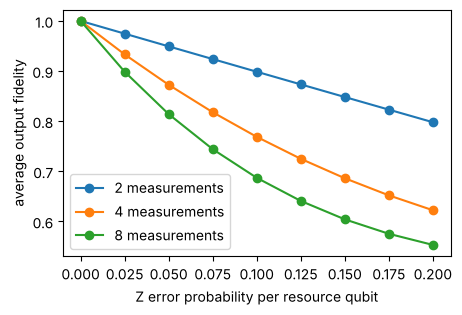

In [2]:
psi = random_state(1, rng)
ps = np.linspace(0, 0.2, 9)
fig, ax = plt.subplots(figsize=(5, 3.2))
for length in (2, 4, 8):
    angles = rng.uniform(0, 2 * np.pi, size=length)
    ax.plot(ps, [noisy_wire_fidelity(psi, angles, p) for p in ps], marker="o", label=f"{length} measurements")
ax.set_xlabel("Z error probability per resource qubit")
ax.set_ylabel("average output fidelity")
ax.legend()
plt.show()

## 2. How entanglement in the resource dies

Dephase every qubit of a 1D cluster ($Z$ with probability $p$) and compute the negativity across the middle cut.
It vanishes *exactly* at $p^* = 1 - 1/\sqrt2 \approx 0.293$, for every length. Why: the CZs away from the cut are local
unitaries on each side and commute with $Z$ errors, so only the two qubits on the bond matter. Their state is a mixture of
four Bell-like states with weights $(1-p)^2, p(1-p), p(1-p), p^2$, entangled iff the largest weight exceeds 1/2.

Bipartite negativity is the coarsest probe. Which *multipartite* entanglement of a patch survives (the part MBQC actually
consumes) needs witnesses for genuine multipartite entanglement; the
[localizable entanglement](https://arxiv.org/abs/quant-ph/0411123) of Popp et al. is the classic bridge between
the two pictures.

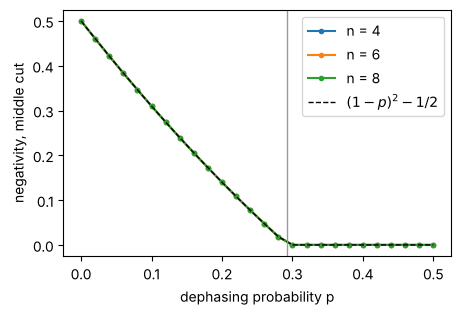

In [3]:
ps = np.linspace(0, 0.5, 26)
fig, ax = plt.subplots(figsize=(5, 3.2))
for n in (4, 6, 8):
    ax.plot(ps, [negativity(dephased_cluster(n, p), n // 2) for p in ps], marker=".", label=f"n = {n}")
ax.plot(ps, np.maximum((1 - ps) ** 2 - 0.5, 0), "k--", lw=1, label="$(1-p)^2 - 1/2$")
ax.axvline(1 - 1 / np.sqrt(2), color="0.6", lw=1)
ax.set_xlabel("dephasing probability p")
ax.set_ylabel("negativity, middle cut")
ax.legend()
plt.show()

## 3. Fusion: gluing small clusters into big ones

A (type-I) fusion takes the end qubits of two graph states and projects them onto $\{|00\rangle, |11\rangle\}$, merging them
into a single vertex whose neighbours are the union. With linear optics it only succeeds half the time; on failure, both qubits
are effectively measured in $Z$, which (lesson 1) deletes them.
[Browne & Rudolph, arXiv:quant-ph/0405157](https://arxiv.org/abs/quant-ph/0405157) showed this is still enough: with 3-qubit
pieces, a success adds 2 qubits and a failure costs 1, so the chain grows on average by $\tfrac12\cdot2 - \tfrac12\cdot1 = 0.5$ per attempt.

success probability 0.500; stabilizers of the 5-qubit chain: [1.0, 1.0, 1.0, 1.0, 1.0]


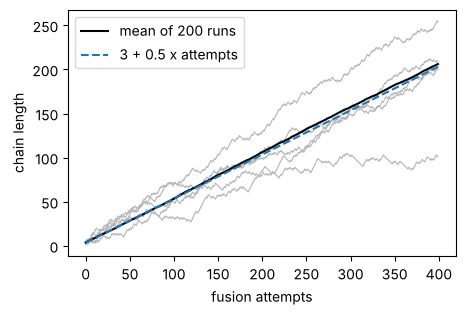

In [4]:
state = graph_state(["a0", "a1", "a2", "b0", "b1", "b2"], [("a0", "a1"), ("a1", "a2"), ("b0", "b1"), ("b1", "b2")])
p = fuse(state, "a2", "b0", "m")
chain = [("a0", "a1"), ("a1", "m"), ("m", "b1"), ("b1", "b2")]
print(f"success probability {p:.3f}; stabilizers of the 5-qubit chain:",
      [round(float(state.expval(stabilizer(chain, q)).real), 6) for q in ["a0", "a1", "m", "b1", "b2"]])

runs = np.array([grow_chain(400, 0.5, rng=rng) for _ in range(200)])
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(runs[:5].T, lw=0.8, color="0.7")
ax.plot(runs.mean(axis=0), color="k", label="mean of 200 runs")
ax.plot(3 + 0.5 * np.arange(1, 401), "--", label="3 + 0.5 x attempts")
ax.set_xlabel("fusion attempts")
ax.set_ylabel("chain length")
ax.legend()
plt.show()

## 4. GKP: why squeezing is the number that matters

A GKP qubit lives in the position $q$ of an oscillator: $|0\rangle$ is a comb of peaks at even multiples of $\sqrt\pi$, $|1\rangle$
at odd multiples. Noise shifts $q$ by a small random amount $\delta$. Error correction rounds to the nearest multiple of
$\sqrt\pi$; it fails when $|\delta|$ is closer to an odd multiple. With finite squeezing, both the states and the noise are
Gaussian with variance set by the squeezing level ($10\log_{10}(\sigma_{\text{vac}}^2/\sigma^2)$ dB). The logical error rate falls
off like a Gaussian tail, which is why squeezing is the key hardware figure in the
[blueprint](https://arxiv.org/abs/2010.02905).

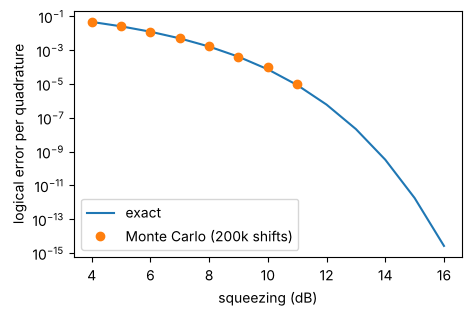

In [5]:
dbs = np.arange(4, 17)
exact = [gkp_error_probability(squeezing_to_sigma(d)) for d in dbs]
mc = [gkp_error_monte_carlo(squeezing_to_sigma(d), 200_000, rng) for d in dbs]
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(dbs, exact, label="exact")
ax.semilogy(dbs, np.where(np.array(mc) > 0, mc, np.nan), "o", label="Monte Carlo (200k shifts)")
ax.set_xlabel("squeezing (dB)")
ax.set_ylabel("logical error per quadrature")
ax.legend()
plt.show()

**Takeaways**
* Pauli noise on the resource turns into flipped outcomes, i.e. logical Pauli errors: trackable and correctable.
* Bipartite entanglement of a dephased cluster dies at $p^*=1-1/\sqrt2$ regardless of size; multipartite structure is the finer question.
* Fusion builds big resources from small ones even when it fails half the time.
* In photonic GKP architectures, squeezing sets the error rate; the 3D cluster turns MBQC into a fault-tolerant surface code.

**Further reading:** [Briegel et al., "Measurement-based quantum computation", arXiv:0910.1116](https://arxiv.org/abs/0910.1116) (review);
blind quantum computing on the brickwork state, [Broadbent, Fitzsimons & Kashefi, arXiv:0807.4154](https://arxiv.org/abs/0807.4154).